In [45]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Definir las variables de entrada y salida difusas
demanda_predicha = ctrl.Antecedent(np.arange(0, 1001, 1), 'demanda_predicha')
impacto_promocion = ctrl.Antecedent(np.arange(0, 1001, 1), 'impacto_promocion')
inventario_rfid = ctrl.Antecedent(np.arange(0, 1001, 1), 'inventario_rfid')

valoracion_situacion = ctrl.Consequent(np.arange(0, 11, 1), 'valoracion_situacion')

# Definir las funciones de membresía para cada variable
demanda_predicha['baja'] = fuzz.trimf(demanda_predicha.universe, [0, 0, 500])
demanda_predicha['media'] = fuzz.trimf(demanda_predicha.universe, [250, 500, 750])
demanda_predicha['alta'] = fuzz.trimf(demanda_predicha.universe, [500, 1000, 1000])

impacto_promocion['bajo'] = fuzz.trimf(impacto_promocion.universe, [0, 0, 500])
impacto_promocion['medio'] = fuzz.trimf(impacto_promocion.universe, [250, 500, 750])
impacto_promocion['alto'] = fuzz.trimf(impacto_promocion.universe, [500, 1000, 1000])

inventario_rfid['bajo'] = fuzz.trimf(inventario_rfid.universe, [0, 0, 500])
inventario_rfid['medio'] = fuzz.trimf(inventario_rfid.universe, [250, 500, 750])
inventario_rfid['alto'] = fuzz.trimf(inventario_rfid.universe, [500, 1000, 1000])

valoracion_situacion['baja'] = fuzz.trimf(valoracion_situacion.universe, [0, 0, 5])
valoracion_situacion['media'] = fuzz.trimf(valoracion_situacion.universe, [2, 5, 8])
valoracion_situacion['alta'] = fuzz.trimf(valoracion_situacion.universe, [5, 10, 10])


e:\fusion_datos\taller final\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


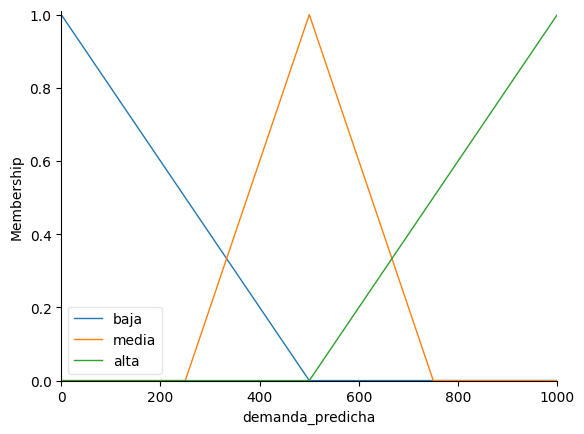

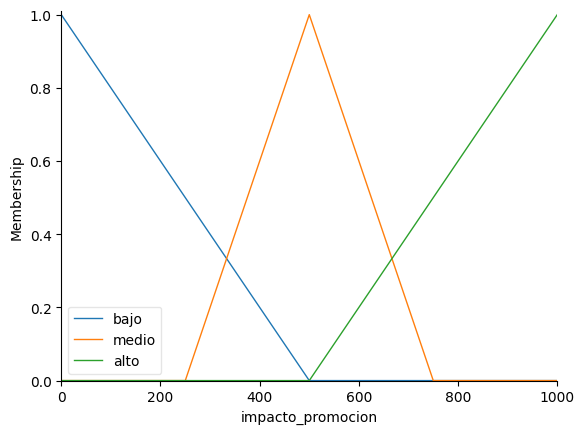

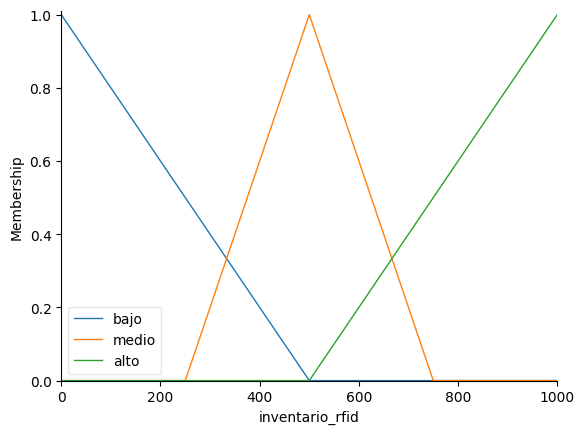

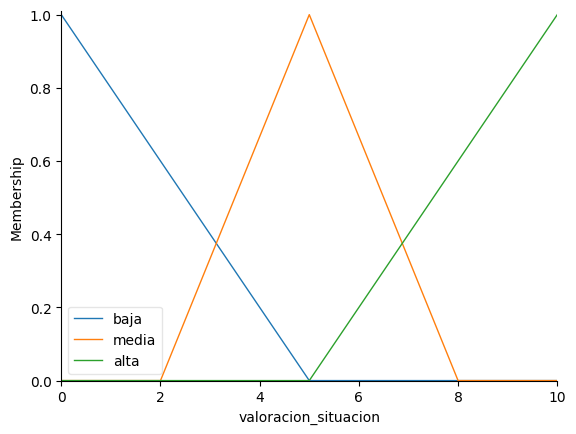

In [46]:

demanda_predicha.view()
impacto_promocion.view()
inventario_rfid.view()
valoracion_situacion.view()

In [47]:
# Crear las reglas difusas
rules = []

# Generando todas las combinaciones posibles para 3 variables con 3 estados cada una
for demanda_level in ['baja', 'media', 'alta']:
    for impacto_level in ['bajo', 'medio', 'alto']:
        for inventario_level in ['bajo', 'medio', 'alto']:
            if demanda_level == 'alta' or impacto_level == 'alto' or inventario_level == 'bajo':
                valoracion_output = 'alta'
            elif demanda_level == 'media' and impacto_level == 'medio' and inventario_level == 'medio':
                valoracion_output = 'media'
            else:
                valoracion_output = 'baja'
            
            # Crear y añadir la regla
            rule = ctrl.Rule(demanda_predicha[demanda_level] & impacto_promocion[impacto_level] & inventario_rfid[inventario_level], valoracion_situacion[valoracion_output])
            rules.append(rule)



In [ ]:
cont=0
for rule in rules:
    cont+=1
    print(rule)
print(cont)

In [49]:
# Crear el sistema de control difuso
valoracion_ctrl = ctrl.ControlSystem(rules)
valoracion = ctrl.ControlSystemSimulation(valoracion_ctrl)

In [50]:
import pandas as pd

# Cargar las predicciones
predicciones_demanda = pd.read_csv('predicciones_demanda_final.csv')
predicciones_impacto_promocion = pd.read_csv('predicciones_inventario_necesario.csv')
predicciones_inventario_rfid = pd.read_csv('predicciones_inventario_rfid.csv')


In [51]:
predicciones_demanda.info()
predicciones_demanda.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 1 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Demanda_Predicha  2000 non-null   int64
dtypes: int64(1)
memory usage: 15.8 KB


,Demanda_Predicha
count,2000.000000
mean,300.898000
std,73.707008
min,146.000000
25%,245.000000
50%,294.500000
75%,349.000000
max,518.000000


In [52]:
predicciones_impacto_promocion.describe()

,Inventario_Necesario
count,2000.00000
mean,2018.46450
std,422.98345
min,1212.00000
25%,1672.75000
50%,2001.00000
75%,2353.50000
max,3113.00000


In [53]:
predicciones_inventario_rfid.describe()


,Inventario_RFID
count,2000.000000
mean,2018.581500
std,422.582801
min,1214.000000
25%,1672.000000
50%,1997.500000
75%,2352.000000
max,3091.000000


In [54]:
# Inicializar la lista para almacenar las valoraciones de la situación
valoraciones = []

# Aplicar el FIS a cada conjunto de predicciones
for i in range(len(predicciones_demanda)):
    valoracion.input['demanda_predicha'] = predicciones_demanda['Demanda_Predicha'][i]
    valoracion.input['impacto_promocion'] = predicciones_impacto_promocion['Inventario_Necesario'][i]
    valoracion.input['inventario_rfid'] = predicciones_inventario_rfid['Inventario_RFID'][i]
    
    # Calcular la valoración de la situación
    valoracion.compute()
    
    # Almacenar la valoración
    valoraciones.append(valoracion.output['valoracion_situacion'])

# Guardar las valoraciones en un archivo CSV
valoraciones_df = pd.DataFrame({'Valoracion_Situacion': valoraciones})
valoraciones_df.to_csv('valoraciones_situacion.csv', index=False)

print("Valoraciones de la situación guardadas en 'valoraciones_situacion.csv'")

Valoraciones de la situación guardadas en 'valoraciones_situacion.csv'


In [55]:
valoraciones_df.info()
valoraciones_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 1 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Valoracion_Situacion  2000 non-null   float64
dtypes: float64(1)
memory usage: 15.8 KB


,Valoracion_Situacion
count,2000.000000
mean,8.050803
std,0.102879
min,7.889600
25%,7.966432
50%,8.040616
75%,8.119957
max,8.333333


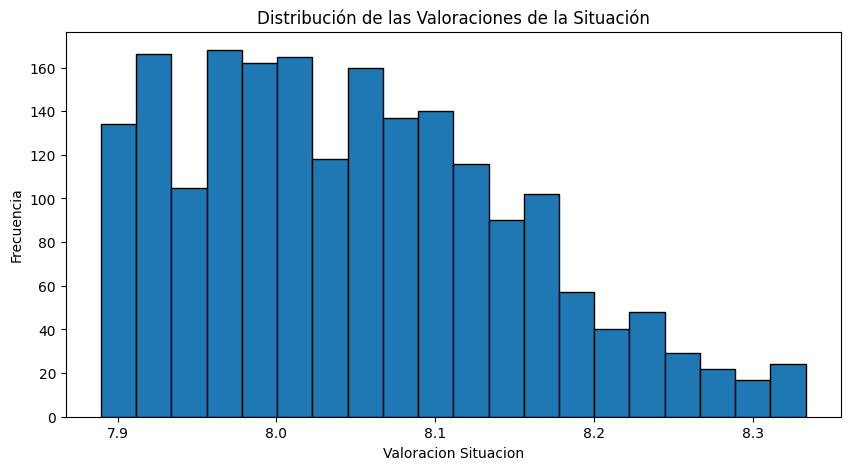

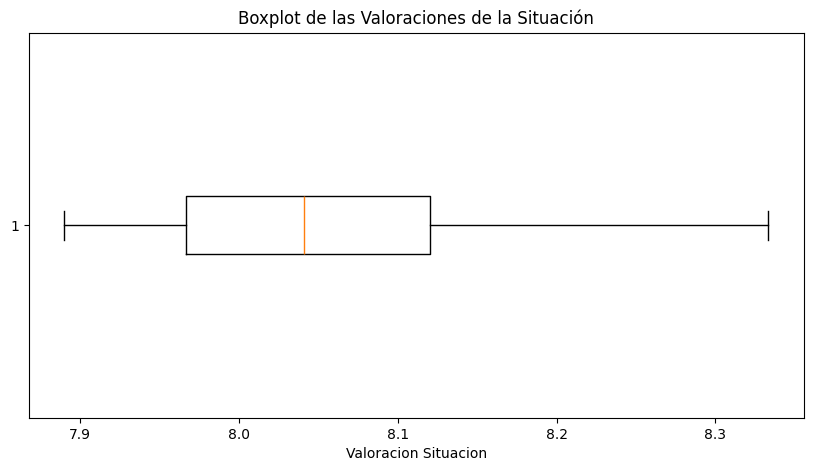

In [56]:
import matplotlib.pyplot as plt

# Histograma
plt.figure(figsize=(10, 5))
plt.hist(valoraciones_df['Valoracion_Situacion'], bins=20, edgecolor='black')
plt.title('Distribución de las Valoraciones de la Situación')
plt.xlabel('Valoracion Situacion')
plt.ylabel('Frecuencia')
plt.show()

# Boxplot
plt.figure(figsize=(10, 5))
plt.boxplot(valoraciones_df['Valoracion_Situacion'], vert=False)
plt.title('Boxplot de las Valoraciones de la Situación')
plt.xlabel('Valoracion Situacion')
plt.show()


In [59]:
import pandas as pd
from pyds import MassFunction

# Cargar las valoraciones
valoraciones_df = pd.read_csv('valoraciones_situacion.csv')

# Definir las funciones de masa iniciales
mass_functions = []

for valoracion in valoraciones_df['Valoracion_Situacion']:
    if valoracion <= 3.33:
        mass_function = MassFunction({frozenset(['baja']): 0.7, frozenset(['media']): 0.2, frozenset(['alta']):0.1})
    elif valoracion <= 6.66:
        mass_function = MassFunction({frozenset(['baja']): 0.2, frozenset(['media']): 0.7, frozenset(['alta']):0.1}) 
    else:
        mass_function = MassFunction({frozenset(['baja']): 0.1, frozenset(['media']): 0.2, frozenset(['alta']):0.7})
    
    mass_functions.append(mass_function)

# Verificar las funciones de masa iniciales
print(f"Mass Functions: {mass_functions[:5]}")  # Imprimir las primeras 5 para verificación

# Combinar las funciones de masa utilizando la regla de combinación de Dempster
combined_mass = mass_functions[0]
for mass_function in mass_functions[1:]:
    combined_mass = combined_mass & mass_function

# Verificar la función de masa combinada
print(f"Combined Mass Function: {combined_mass}")

# Obtener la creencia, plausibilidad y probabilidad pignística de la valoración final
belief_baja = combined_mass.bel(frozenset(['baja']))
belief_media = combined_mass.bel(frozenset(['media']))
belief_alta = combined_mass.bel(frozenset(['alta']))

plausibility_baja = combined_mass.pl(frozenset(['baja']))
plausibility_media = combined_mass.pl(frozenset(['media']))
plausibility_alta = combined_mass.pl(frozenset(['alta']))

pignistic = combined_mass.pignistic()

print(f"Creencia Baja: {belief_baja}")
print(f"Creencia Media: {belief_media}")
print(f"Creencia Alta: {belief_alta}")
print(f"Plausibilidad Baja: {plausibility_baja}")
print(f"Plausibilidad Media: {plausibility_media}")
print(f"Plausibilidad Alta: {plausibility_alta}")
print(f"Probabilidad Pignística: {pignistic}")

# Guardar los resultados en un archivo CSV
resultados_df = pd.DataFrame({
    'Creencia_Baja': [belief_baja], 
    'Creencia_Media': [belief_media], 
    'Creencia_Alta': [belief_alta],
    'Plausibilidad_Baja': [plausibility_baja], 
    'Plausibilidad_Media': [plausibility_media], 
    'Plausibilidad_Alta': [plausibility_alta],
    'Probabilidad_Pignistica_Baja': [pignistic.get(frozenset(['baja']), 0)],
    'Probabilidad_Pignistica_Media': [pignistic.get(frozenset(['media']), 0)],
    'Probabilidad_Pignistica_Alta': [pignistic.get(frozenset(['alta']), 0)]
})
resultados_df.to_csv('resultados_dempster_shafer.csv', index=False)

print("Resultados de Dempster-Shafer guardados en 'resultados_dempster_shafer.csv'")


Mass Functions: [{frozenset({'baja'}): 0.1, frozenset({'media'}): 0.2, frozenset({'alta'}): 0.7}, {frozenset({'baja'}): 0.1, frozenset({'media'}): 0.2, frozenset({'alta'}): 0.7}, {frozenset({'baja'}): 0.1, frozenset({'media'}): 0.2, frozenset({'alta'}): 0.7}, {frozenset({'baja'}): 0.1, frozenset({'media'}): 0.2, frozenset({'alta'}): 0.7}, {frozenset({'baja'}): 0.1, frozenset({'media'}): 0.2, frozenset({'alta'}): 0.7}]
Combined Mass Function: {{'alta'}:1.0; {'baja'}:0.0; {'media'}:0.0}
Creencia Baja: 0.0
Creencia Media: 0.0
Creencia Alta: 1.0
Plausibilidad Baja: 0.0
Plausibilidad Media: 0.0
Plausibilidad Alta: 1.0
Probabilidad Pignística: {{'alta'}:1.0}
Resultados de Dempster-Shafer guardados en 'resultados_dempster_shafer.csv'


In [75]:
resultados_df


,Creencia_Baja,Creencia_Media,Creencia_Alta,Plausibilidad_Baja,Plausibilidad_Media,Plausibilidad_Alta,Probabilidad_Pignistica_Baja,Probabilidad_Pignistica_Media,Probabilidad_Pignistica_Alta
0,0.0,0.0,1.0,0.0,0.0,1.0,0,0,1.0


In [60]:
# Verificar las funciones de masa iniciales
for i, mass_function in enumerate(mass_functions[:5]):
    print(f"Mass Function {i}: {mass_function}")

# Verificar la función de masa combinada
print(f"Combined Mass Function: {combined_mass}")


Mass Function 0: {{'alta'}:0.7; {'media'}:0.2; {'baja'}:0.1}
Mass Function 1: {{'alta'}:0.7; {'media'}:0.2; {'baja'}:0.1}
Mass Function 2: {{'alta'}:0.7; {'media'}:0.2; {'baja'}:0.1}
Mass Function 3: {{'alta'}:0.7; {'media'}:0.2; {'baja'}:0.1}
Mass Function 4: {{'alta'}:0.7; {'media'}:0.2; {'baja'}:0.1}
Combined Mass Function: {{'alta'}:1.0; {'baja'}:0.0; {'media'}:0.0}
